In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("/content/netflix_users.csv")

       User_ID              Name  Age    Country Subscription_Type  \
0            1    James Martinez   18     France           Premium   
1            2       John Miller   23        USA           Premium   
2            3        Emma Davis   60         UK             Basic   
3            4       Emma Miller   44        USA           Premium   
4            5        Jane Smith   68        USA          Standard   
...        ...               ...  ...        ...               ...   
24995    24996      David Miller   18  Australia           Premium   
24996    24997       Jane Miller   17        USA           Premium   
24997    24998      Sarah Miller   14        USA           Premium   
24998    24999  Michael Williams   71        USA             Basic   
24999    25000       James Jones   19    Germany           Premium   

       Watch_Time_Hours Favorite_Genre  Last_Login  
0                 80.26          Drama  2024-05-12  
1                321.75         Sci-Fi  2025-02-05  


'A'

In [ ]:
features = [
    "Age",
    "Watch_Time_Hours"
]

In [ ]:
df = df.dropna(subset=features)

# Create the feature matrix
X = df[features]
# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


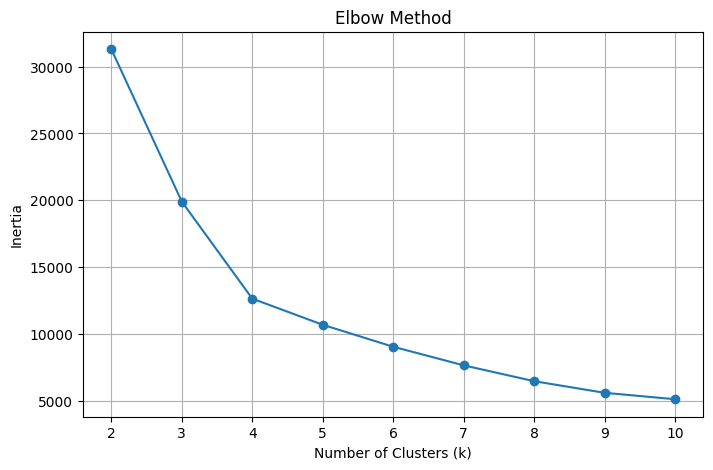


Inertia Values
----------------
k = 2: 31293.98
k = 3: 19901.93
k = 4: 12648.38
k = 5: 10694.07
k = 6: 9051.64
k = 7: 7662.67
k = 8: 6478.40
k = 9: 5608.31
k = 10: 5127.90


In [ ]:
# -----------------------------
# Elbow Method
# -----------------------------

inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertias.append(model.inertia_)

# Plot the elbow curve
plt.figure(figsize=(8,5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(True)
plt.show()

# Print inertia values
print("\nInertia Values")
print("----------------")

for i, value in enumerate(inertias):
    print(f"k = {i+2}: {value:.2f}")

In [ ]:
model = KMeans(n_clusters=3, random_state=1)
labels = model.fit_predict(X_scaled)

df['cluster'] = labels
print(df['cluster'].value_counts())

cluster
1    9445
0    7904
2    7651
Name: count, dtype: int64


In [ ]:
print(df.groupby('cluster').mean(numeric_only=True))

              User_ID        Age  Watch_Time_Hours
cluster                                           
0        12631.826544  28.297191        676.005830
1        12465.238327  46.875490        201.075361
2        12408.360606  64.785257        688.722336


In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
df['cluster']


,cluster
0,0
1,0
2,0
3,0
4,2
...,...
24995,0
24996,0
24997,0
24998,2


In [ ]:
# -----------------------------
# Cluster Sizes
# -----------------------------

print("\nCluster Sizes")
print("----------------")
print(df["cluster"].value_counts().sort_index())


Cluster Sizes
----------------
cluster
0    7824
1    7774
2    9402
Name: count, dtype: int64


In [ ]:
# -----------------------------
# Cluster Summary Statistics
# -----------------------------

print("\nCluster Summary")
print("----------------")

cluster_summary = df.groupby("cluster")[features].mean()

print(cluster_summary)


Cluster Summary
----------------
               Age  Watch_Time_Hours
cluster                             
0        28.297191        676.005830
1        46.875490        201.075361
2        64.785257        688.722336


In [ ]:
# See the top favorite genre percentages for each cluster
for cluster_id in sorted(df['cluster'].unique()):
    print(f"\n--- Cluster {cluster_id} Genre Proportions ---")
    genre_proportions = df[df['cluster'] == cluster_id]['Favorite_Genre'].value_counts(normalize=True) * 100
    print(genre_proportions.round(2)) # Prints percentages rounded to 2 decimal places


--- Cluster 0 Genre Proportions ---
Favorite_Genre
Romance        14.92
Horror         14.79
Documentary    14.33
Comedy         14.27
Action         14.02
Sci-Fi         13.93
Drama          13.74
Name: proportion, dtype: float64

--- Cluster 1 Genre Proportions ---
Favorite_Genre
Horror         15.03
Action         14.61
Documentary    14.49
Drama          14.09
Romance        14.02
Comedy         13.97
Sci-Fi         13.79
Name: proportion, dtype: float64

--- Cluster 2 Genre Proportions ---
Favorite_Genre
Documentary    14.82
Drama          14.59
Comedy         14.56
Action         14.39
Romance        13.97
Horror         13.92
Sci-Fi         13.75
Name: proportion, dtype: float64


In [55]:
# Loop through each cluster and extract 2 sample users
for cluster_id in sorted(df['cluster'].unique()):
    print(f"\n==============================")
    print(f"Sample Users for Cluster {cluster_id}")
    print(f"==============================")

    # Filter rows for the current cluster and grab the first 2
    sample_users = df[df['cluster'] == cluster_id].head(2)

    print(sample_users[['Name', 'Age', 'Watch_Time_Hours', 'Favorite_Genre', 'Subscription_Type']])


Sample Users for Cluster 0
            Name  Age  Watch_Time_Hours Favorite_Genre Subscription_Type
1    John Miller   23            321.75         Sci-Fi           Premium
5  David Johnson   21            615.93        Romance          Standard

Sample Users for Cluster 1
             Name  Age  Watch_Time_Hours Favorite_Genre Subscription_Type
0  James Martinez   18             80.26          Drama           Premium
2      Emma Davis   60             35.89         Comedy             Basic

Sample Users for Cluster 2
             Name  Age  Watch_Time_Hours Favorite_Genre Subscription_Type
4      Jane Smith   68            909.30          Drama          Standard
6  John Hernandez   57            755.47        Romance          Standard
